## Notebook 6 – Multivariate Analysis

Multivariate Analysis is a data analysis technique used to study relationships among three or more variables simultaneously

In data analysis, it helps us understand how multiple features work together, identify patterns, discover relationships, and select useful features for Machine Learning models

For example, in an employee dataset, we might analyze how Age, Experience, Education, and Department relate to Salary

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Age": [22, 25, 28, 30, 32, 35, 38, 40, 42, 45],
    "Experience": [1, 3, 5, 6, 8, 10, 12, 15, 16, 20],
    "Salary": [25000, 30000, 35000, 40000, 45000,
               50000, 55000, 65000, 68000, 80000],
    "PerformanceScore": [60, 65, 70, 68, 75, 80, 78, 85, 82, 92],
    "Department": ["IT", "HR", "IT", "Sales", "HR",
                   "IT", "Sales", "IT", "HR", "Sales"]
})

df.head()

,Age,Experience,Salary,PerformanceScore,Department
0,22,1,25000,60,IT
1,25,3,30000,65,HR
2,28,5,35000,70,IT
3,30,6,40000,68,Sales
4,32,8,45000,75,HR



  ### Correlation Matrix
  

A correlation matrix is a table that displays the correlation coefficients between pairs of numerical variables.

The Pearson correlation coefficient ranges from -1 to +1.

$$
r = \frac{\operatorname{Cov}(X,Y)}{\sigma_X \sigma_Y}
$$

Where:

- $r$ = correlation coefficient
- $\operatorname{Cov}(X,Y)$ = covariance between two variables
- $\sigma_X, \sigma_Y$ = standard deviations of the variables


Interpretation:

Correlation         	Meaning

Close to +1	        Strong positive linear relationship

Close to 0      	Weak or no linear relationship

Close to -1	        Strong negative linear relationship

A correlation close to zero does not necessarily mean there is no relationship; a nonlinear relationship may still exist.

In [2]:

numerical_df = df.select_dtypes(include="number")

correlation_matrix = numerical_df.corr()

correlation_matrix.round(2)

,Age,Experience,Salary,PerformanceScore
Age,1.00,0.99,0.99,0.97
Experience,0.99,1.00,1.00,0.97
Salary,0.99,1.00,1.00,0.97
PerformanceScore,0.97,0.97,0.97,1.00


### Heatmap

A heatmap represents the correlation matrix using colors. It makes it easier to identify strong positive and negative relationships across many numerical features

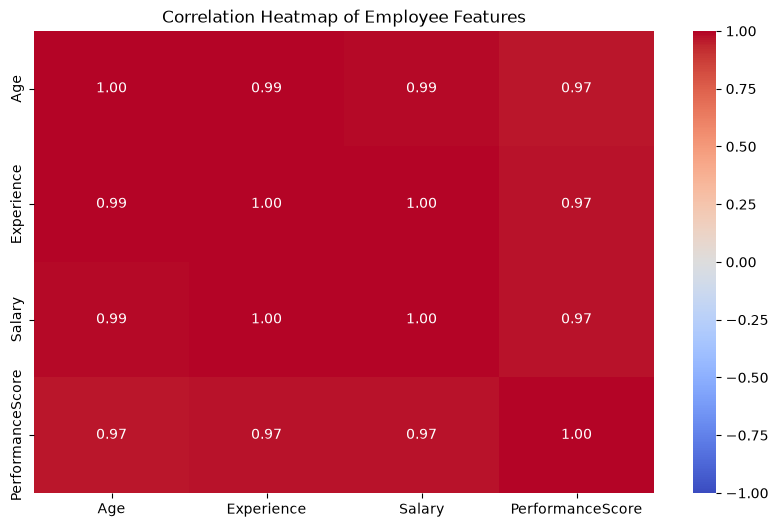

In [3]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Employee Features")
plt.show()

How to interpret the visualization:

- Values near +1 indicate strong positive linear correlation
- Values near -1 indicate strong negative linear correlation
- Values near 0 indicate weak linear correlation
- The diagonal always contains 1.00, because each variable is perfectly correlated with itself

Finding to document: Check which feature pairs have the largest absolute correlation coefficients. These pairs deserve further investigation, especially if they are intended to be predictors in the same Machine Learning model

### Pair Plot

A pair plot displays relationships between multiple numerical variables using scatter plots. The diagonal usually shows each variable's distribution

It helps identify:

- Positive and negative relationships
- Outliers
- Clusters and groups
- Nonlinear patterns
- Potentially useful features for prediction

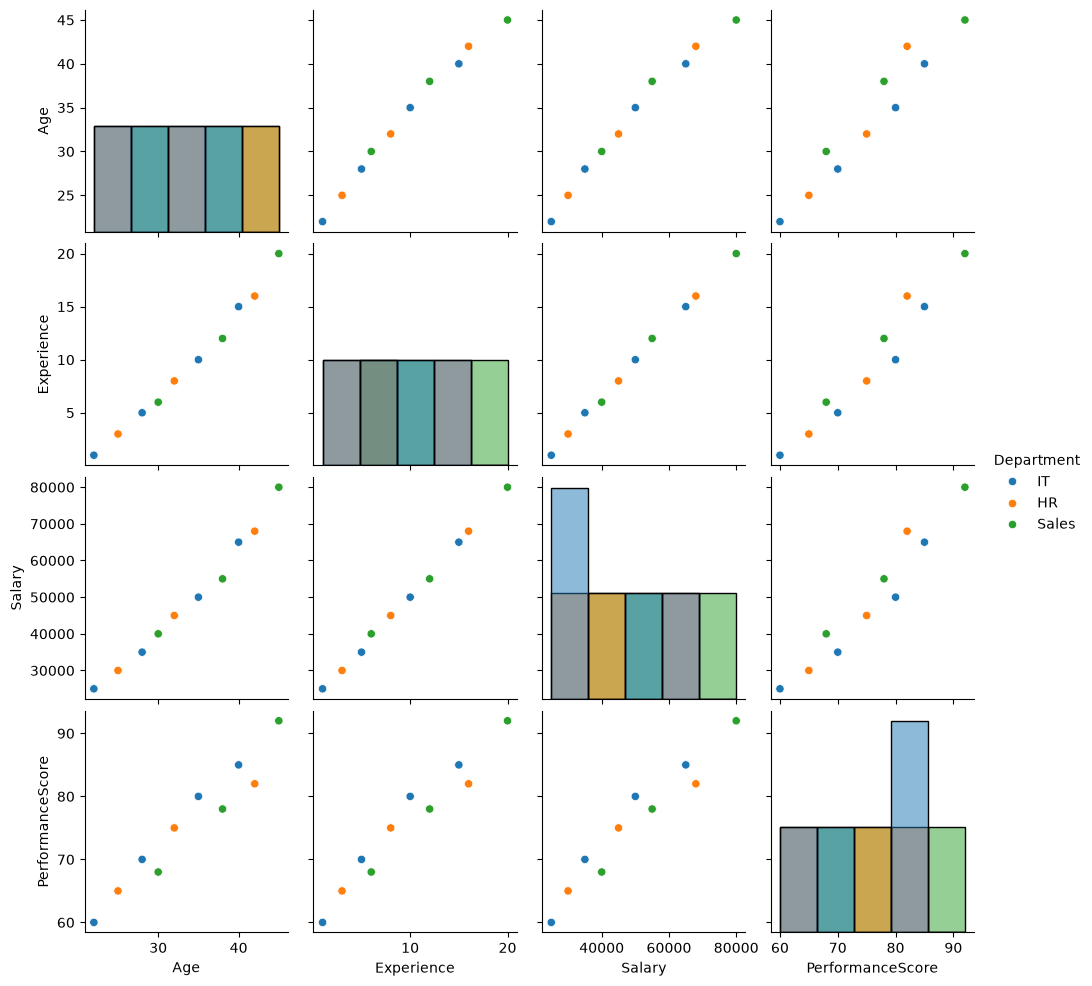

In [4]:
sns.pairplot(
    df,
    vars=[
        "Age",
        "Experience",
        "Salary",
        "PerformanceScore"
    ],
    hue="Department",
    diag_kind="hist"
)

plt.show()

Interpretation: Each off-diagonal plot compares two features. The diagonal shows the distribution of an individual feature. Different colors represent departments, allowing you to investigate whether the relationships differ across groups

### Multiple Feature Relationships

Sometimes, one variable cannot explain an outcome by itself. We need to examine multiple features together.

For example, employee salary might be associated with both experience and performance.

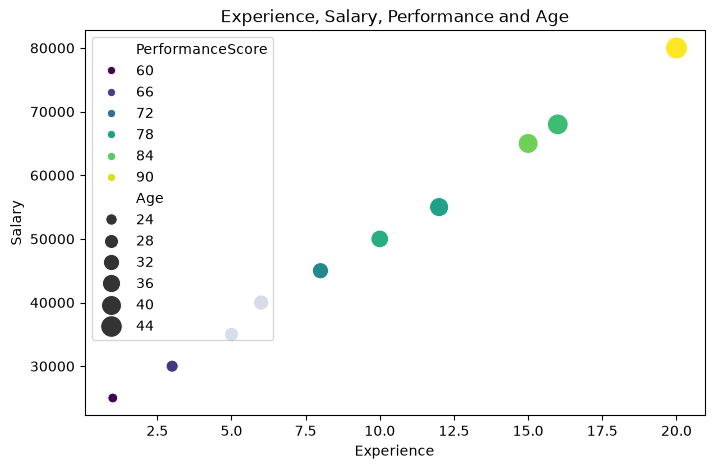

In [5]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Experience",
    y="Salary",
    hue="PerformanceScore",
    size="Age",
    palette="viridis",
    sizes=(50, 250)
)

plt.title("Experience, Salary, Performance and Age")
plt.show()

Here:

- X-axis represents experience
- Y-axis represents salary
- Color represents performance score
- Point size represents age
- 
Finding to document: Examine whether salary tends to increase with experience and whether employees with higher performance scores also tend to earn more. These are patterns in the sample, not proof of causation.

### Feature Interactions

A feature interaction occurs when the relationship between one feature and the target changes depending on the value of another feature

For example, the relationship between experience and salary might differ by department

One way to investigate this is to compare the experience–salary relationship across departments

<Figure size 800x500 with 0 Axes>

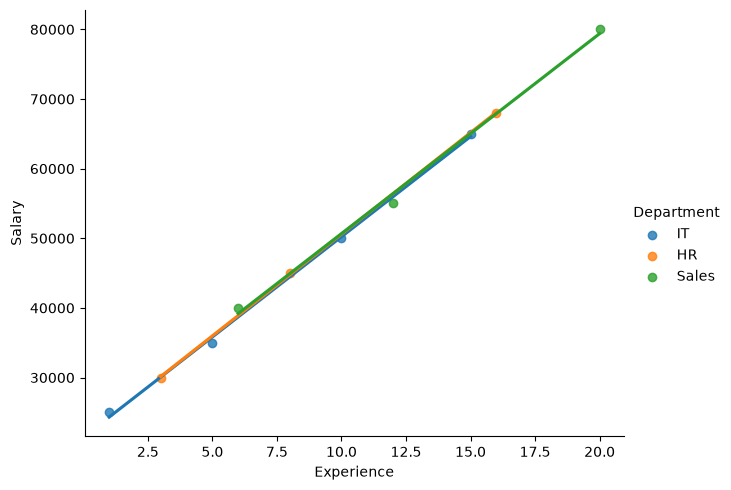

In [6]:
plt.figure(figsize=(8, 5))

sns.lmplot(
    data=df,
    x="Experience",
    y="Salary",
    hue="Department",
    height=5,
    aspect=1.3,
    ci=None
)

plt.show()

This produces a separate fitted trend line for each department

If the lines have noticeably different slopes, that may suggest the relationship between experience and salary varies by department. However, the sample is small, so a larger dataset would be needed to assess this reliably.

An interaction can also be represented mathematically:

$$
\text{Salary} =
\beta_0 + \beta_1(\text{Experience})
+ \beta_2(\text{Performance})
+ \beta_3(\text{Experience} \times \text{Performance})
$$

The interaction term is:

$$
\text{Experience} \times \text{Performance}
$$

If the interaction coefficient \(\beta_3\) is meaningfully different from zero, it suggests that the association between experience and salary changes with performance, subject to the model assumptions and statistical uncertainty.

### Numerical Feature Relationships

Numerical features can be examined using correlation coefficients and scatter plots.

In [7]:

corr_pairs = (
    correlation_matrix
    .where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]

corr_pairs["Absolute_Correlation"] = (
    corr_pairs["Correlation"].abs()
)

corr_pairs.sort_values(
    by="Absolute_Correlation",
    ascending=False
)

,Feature_1,Feature_2,Correlation,Absolute_Correlation
6,Experience,Salary,0.999142,0.999142
1,Age,Experience,0.993030,0.993030
2,Age,Salary,0.990123,0.990123
7,Experience,PerformanceScore,0.973944,0.973944
11,Salary,PerformanceScore,0.969996,0.969996
3,Age,PerformanceScore,0.968250,0.968250
0,Age,Age,NaN,NaN
4,Experience,Age,NaN,NaN
5,Experience,Experience,NaN,NaN
8,Salary,Age,NaN,NaN
